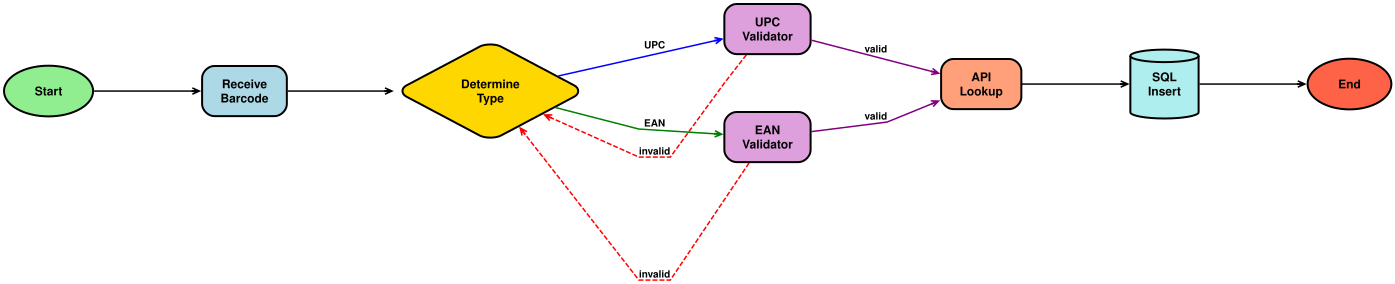

In [1]:
import networkx as nx
from IPython.display import SVG, display
import os, tempfile

G = nx.DiGraph()
nodes = {
    "Start": {
        "label": "Start",
        "shape": "ellipse",
        "fillcolor": "lightgreen",
        "group": "terminal",
    },

    "Receive Barcode": {
        "label": "Receive\nBarcode",
        "shape": "box",
        "fillcolor": "lightblue",
        "group": "process",
    },

    "Determine Type": {
        "label": "Determine\nType",
        "shape": "diamond",
        "fillcolor": "gold",
        "group": "decision",
    },

    "UPC Validator": {
        "label": "UPC\nValidator",
        "shape": "box",
        "fillcolor": "plum",
        "group": "validator",
    },

    "EAN Validator": {
        "label": "EAN\nValidator",
        "shape": "box",
        "fillcolor": "plum",
        "group": "validator",
    },

    "API Lookup": {
        "label": "API\nLookup",
        "shape": "box",
        "fillcolor": "lightsalmon",
        "group": "api",
    },

    "SQL Insert": {
        "label": "SQL\nInsert",
        "shape": "cylinder",
        "fillcolor": "paleturquoise",
        "group": "database",
    },

    "End": {
        "label": "End",
        "shape": "ellipse",
        "fillcolor": "tomato",
        "group": "terminal",
    },
}
for node, attrs in nodes.items():
    G.add_node(node, **attrs)

edges = [
    ("Start", "Receive Barcode", {
        "label": "",
        "color": "black",
        "style": "solid",
    }),

    ("Receive Barcode", "Determine Type", {
        "label": "",
        "color": "black",
        "style": "solid",
    }),

    ("Determine Type", "UPC Validator", {
        "label": "UPC",
        "color": "blue",
        "style": "solid",
    }),

    ("Determine Type", "EAN Validator", {
        "label": "EAN",
        "color": "green",
        "style": "solid",
    }),

    ("UPC Validator", "API Lookup", {
        "label": "valid",
        "color": "purple",
        "style": "solid",
    }),

    ("EAN Validator", "API Lookup", {
        "label": "valid",
        "color": "purple",
        "style": "solid",
    }),

    ("UPC Validator", "Determine Type", {
        "label": "invalid",
        "color": "red",
        "style": "dashed",
        "constraint": "false",
    }),

    ("EAN Validator", "Determine Type", {
        "label": "invalid",
        "color": "red",
        "style": "dashed",
        "constraint": "false",
    }),

    ("API Lookup", "SQL Insert", {
        "label": "",
        "color": "black",
        "style": "solid",
    }),

    ("SQL Insert", "End", {
        "label": "",
        "color": "black",
        "style": "solid",
    }),
]
for u, v, attrs in edges:
    G.add_edge(u, v, **attrs)

A = nx.nx_agraph.to_agraph(G)
A.graph_attr.update(rankdir="LR",ranksep="1.5",nodesep="0.8",splines="polyline",bgcolor="white",)
A.node_attr.update(style="rounded,filled",fontname="Helvetica-Bold",fontsize="12",penwidth="2",margin="0.25,0.15",)
A.edge_attr.update(fontname="Helvetica-Bold",fontsize="10",penwidth="1.5",arrowsize="0.7",arrowhead="vee",)

for node, attrs in nodes.items():
    n = A.get_node(node)
    n.attr.update(label=attrs["label"],shape=attrs["shape"],fillcolor=attrs["fillcolor"],)


for u, v, attrs in edges:
    e = A.get_edge(u, v)
    e.attr.update(label=attrs.get("label", ""),color=attrs.get("color", "black"),style=attrs.get("style", "solid"),)
    if "constraint" in attrs:
        e.attr["constraint"] = attrs["constraint"]

with tempfile.NamedTemporaryFile(suffix=".svg", delete=False) as f:
    filename = f.name

try:
    A.draw(filename,format="svg",prog="dot")
    display(SVG(filename))

finally:
    os.remove(filename)

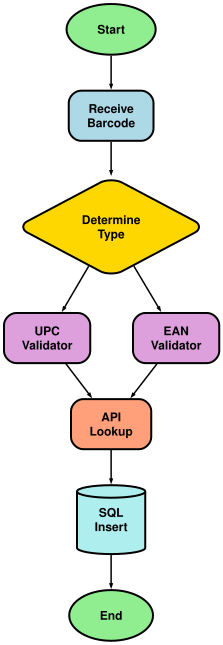

In [ ]:


nodes = {
    "start": {"label": "Start", "type": "terminal",},
    "receive": {"label": "Receive\nBarcode","type": "process",},
    "detect": {"label": "Determine\nType", "type": "decision",},
    "upc": {"label": "UPC\nValidator","type": "validator",},
    "ean": {"label": "EAN\nValidator","type": "validator",},
    "api": {"label": "API\nLookup","type": "external",},
    "sql": {"label": "SQL\nInsert", "type": "database",},
    "end": {"label": "End","type": "terminal",},
}


edges = [
    ("start", "receive"),
    ("receive", "detect"),
    ("detect", "upc"),
    ("detect", "ean"),
    ("upc", "api"),
    ("ean", "api"),
    ("api", "sql"),
    ("sql", "end"),
]

node_styles = {

    "terminal": {
        "shape": "ellipse",
        "fillcolor": "lightgreen",
    },

    "process": {
        "shape": "box",
        "fillcolor": "lightblue",
    },

    "decision": {
        "shape": "diamond",
        "fillcolor": "gold",
    },

    "validator": {
        "shape": "box",
        "fillcolor": "plum",
    },

    "external": {
        "shape": "box",
        "fillcolor": "lightsalmon",
    },

    "database": {
        "shape": "cylinder",
        "fillcolor": "paleturquoise",
    },
}

edge_styles = {

    "normal": {
        "color": "black",
        "style": "solid",
    },

    "valid": {
        "color": "purple",
        "style": "solid",
    },

    "invalid": {
        "color": "red",
        "style": "dashed",
        "constraint": "false",
    }
}

graph_style = {
    "graph": {"rankdir": "TB","ranksep": "0.5","nodesep": "0.6","splines": "polyline",},
    "node": {"style": "rounded,filled","fontname": "Helvetica-Bold","fontsize": "12","penwidth": "2","margin": "0.25,0.15",},
    "edge": {"fontname": "Helvetica-Bold","fontsize": "10","penwidth": "1.5","arrowsize": "0.3","arrowhead": "normal",}
}

def build_graph(nodes, edges):
    G = nx.DiGraph()

    # Add nodes with semantic attributes
    for node_id, attrs in nodes.items():
        G.add_node(node_id, **attrs)

    # Add edges
    for edge in edges:
        G.add_edge(*edge)

    return G

def style_graphviz(G,node_styles,edge_styles,graph_style):
    A = nx.nx_agraph.to_agraph(G)

    # Apply global graph attributes
    A.graph_attr.update(graph_style["graph"])
    A.node_attr.update(graph_style["node"])
    A.edge_attr.update(graph_style["edge"])

    # Apply node-specific styles
    for node_id in G.nodes():
        node_type = G.nodes[node_id]["type"]
        if node_type in node_styles:
            A.get_node(node_id).attr.update(node_styles[node_type])

    # Apply edge-specific styles
    for u, v in G.edges():
        edge_data = G.get_edge_data(u, v)
        edge_type = edge_data.get("type", "normal")
        if edge_type in edge_styles:
            A.get_edge(u, v).attr.update(edge_styles[edge_type])

    return A

def display_graph(A):
    with tempfile.NamedTemporaryFile(suffix=".svg", delete=False) as f:
        filename = f.name
    try:
        A.draw(filename,format="svg",prog="dot")
        display(SVG(filename))
    finally:
        os.remove(filename)


#G = build_graph(nodes, edges)
#A = style_graphviz(G, node_styles, edge_styles, graph_style)
#display_graph(A)

# Graphviz Visualization Options

This section summarizes common Graphviz settings used for process diagrams.

---

## Arrowheads

Arrowheads are controlled with the `arrowhead` edge attribute.

Example:

```python
A.edge_attr.update(
    arrowhead="vee"
)
```

| Option    | Description                              |
| --------- | ---------------------------------------- |
| `normal`  | Standard filled arrow                    |
| `vee`     | Open V-shaped arrow (good for workflows) |
| `dot`     | Filled circular endpoint                 |
| `odot`    | Open circular endpoint                   |
| `diamond` | Diamond-shaped endpoint                  |
| `crow`    | Crow-foot notation                       |
| `tee`     | Perpendicular bar                        |
| `box`     | Square endpoint                          |
| `none`    | No arrowhead                             |


## Nodeshapes

Similarly, controlled with `shape` in node attribute.

```python
A.node_attr.update(
    shape="box"
)
```
| Shape           | Use                          |
| --------------- | ---------------------------- |
| `ellipse`       | Start/end states             |
| `box`           | Process steps                |
| `rounded`       | Rounded process boxes        |
| `diamond`       | Decision points              |
| `cylinder`      | Databases                    |
| `hexagon`       | Preparation/validation steps |
| `parallelogram` | Input/output                 |
| `folder`        | Files                        |
| `component`     | Software components          |
| `note`          | Annotations                  |
| `record`        | Structured information       |

## Layout Direction 

```python
A.graph_attr.update(
    rankdir="LR"
)
```
| Value | Direction    | Use                |
| ----- | ------------ | ------------------ |
| `TB`  | Top → Bottom | Default flowcharts |
| `BT`  | Bottom → Top | Reverse flow       |
| `LR`  | Left → Right | Process pipelines  |
| `RL`  | Right → Left | Reverse pipelines  |

Note that `ranksep` will determine distance between nodes

## Edge Routing (Splines)

```python
A.graph_attr.update(
    splines="polyline"
)
```
| Option     | Description                  | Best use              |
| ---------- | ---------------------------- | --------------------- |
| `line`     | Straight lines               | Simple graphs         |
| `polyline` | Straight segments with bends | Process diagrams      |
| `spline`   | Curved edges                 | Complex networks      |
| `curved`   | Curved paths                 | Relationship diagrams |
| `ortho`    | Orthogonal 90° routing       | Flowcharts            |
| `false`    | Disable routing              | Basic layouts         |


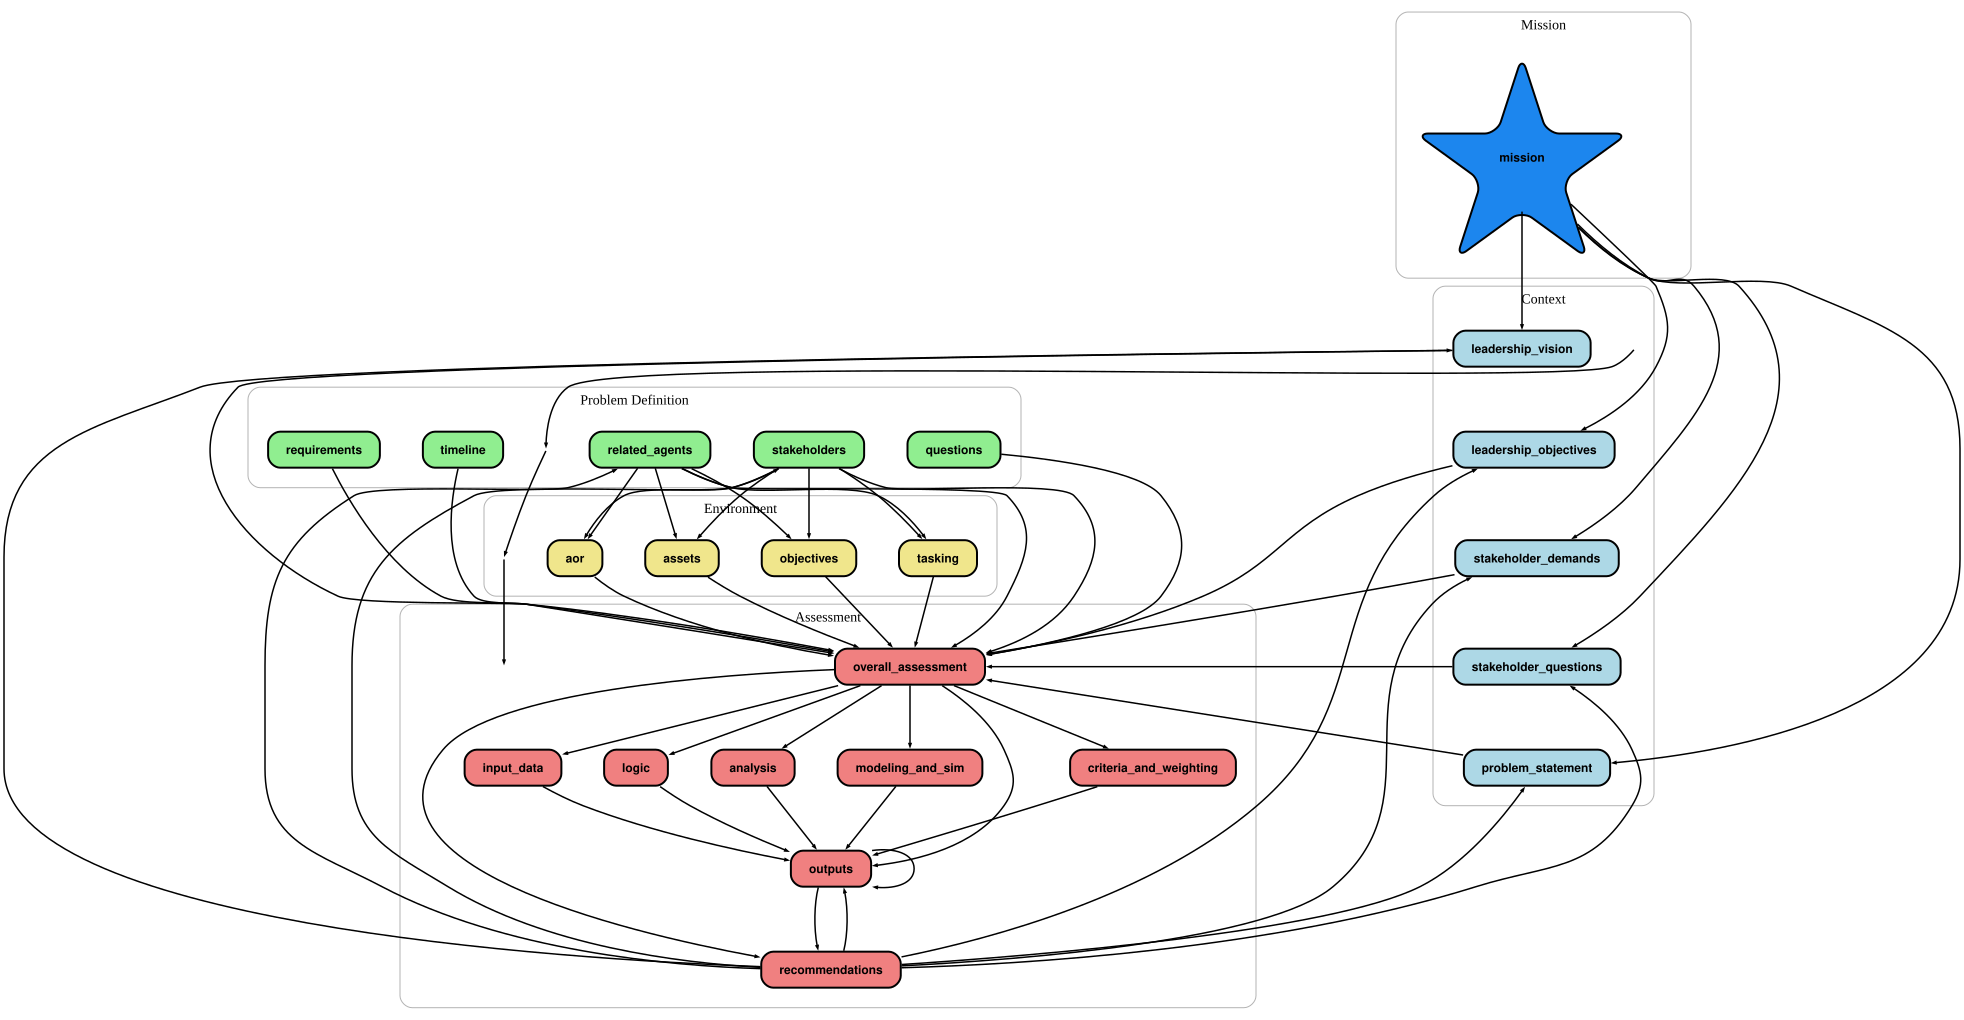

In [17]:
import networkx as nx
from IPython.display import SVG, display
import os, tempfile

# Primary Nodes
nodes = {
    "Mission": ["mission"],
    "Context": ["leadership_vision","leadership_objectives","stakeholder_demands","stakeholder_questions","problem_statement",],
    "Problem Definition": ["stakeholders","related_agents","questions","requirements","timeline",],
    "Environment": ["aor","assets","objectives","tasking",],
    "Assessment": ["overall_assessment","criteria_and_weighting","input_data","logic", "analysis", "modeling_and_sim", "outputs","recommendations",],
}

# Metadata Tags
stage_style = {
    "Mission": dict(fillcolor="dodgerblue2", shape="star"),
    "Context": dict(fillcolor="lightblue", shape="box"),
    "Problem Definition": dict(fillcolor="lightgreen", shape="box"),
    "Environment": dict(fillcolor="khaki", shape="box"),
    "Assessment": dict(fillcolor="lightcoral", shape="box"),
}

categories = {
    "Drivers": ["mission","leadership_vision","leadership_objectives","stakeholder_demands","stakeholder_questions","problem_statement",],
    "Demands": ["stakeholders","related_agents","questions","requirements","timeline",],
    "Agent_Attributes": ["aor","assets","objectives","tasking",],
    "Assessment": ["overall_assessment","criteria_and_weighting","input_data","logic", "analysis", "modeling_and_sim",],
    "Deliverables": ["outputs","recommendations",],
    }

# Relationship dictionary
edges = {
    "mission": [("mission", item) for item in nodes["Context"]],
    #"relational_context": [(item1, item2) for item1 in nodes["Context"] for item2 in nodes["Context"] if item1 != item2],
    "ownership": [(agent, item) for agent in ["stakeholders", "related_agents"] for item in nodes["Environment"]],
    #"problem_space_interdependencies": [(item1, item2) for item1 in nodes["Problem Definition"] for item2 in nodes["Problem Definition"] if item1 != item2],
    "problem_informing_assessment": [(item, "overall_assessment") for item in nodes["Problem Definition"]],
    "agent_properties_informing_assessment": [(item, "overall_assessment") for item in nodes["Environment"]],
    "leadership_informing_assessment": [(item, "overall_assessment") for item in nodes["Context"]],
    "assessment_includes": [("overall_assessment", item) for item in nodes["Assessment"] if item != "overall_assessment"],
    #"assessment_interdependencies": [(item1, item2) for item1 in nodes["Assessment"] for item2 in nodes["Assessment"] if item1 != item2],
    "utilized_to_produce_outputs": [(item, "outputs") for item in nodes["Assessment"] if item != "overall_assessment"],
    "assessment_to_deliverables": [("outputs", "recommendations")],
    "recommendation_feed": [("recommendations", item) for item in nodes["Context"] + ["stakeholders", "related_agents"]],
}

G = nx.DiGraph()
for stage, items in nodes.items():
    for item in items:
        G.add_node(
            item,stage=stage,
            category=[c for c, vals in categories.items() if item in vals][0],
            **stage_style[stage],
        )

for relation, edge_list in edges.items():
    for u, v in edge_list:
        G.add_edge(u, v, relation=relation)       

graph_style = {
    "graph": {"rankdir": "TB","ranksep": "0.9","nodesep": "0.6","splines": "spline",},
    "node": {"style": "rounded,filled","fontname": "Helvetica-Bold","fontsize": "12","penwidth": "2","margin": "0.25,0.15",},
    "edge": {"fontname": "Helvetica-Bold","fontsize": "10","penwidth": "1.5","arrowsize": "0.3","arrowhead": "normal",}
}


# Write the attributes
A = nx.nx_agraph.to_agraph(G)
A.graph_attr.update(graph_style["graph"])
A.node_attr.update(graph_style["node"])
A.edge_attr.update(graph_style["edge"])
A.graph_attr["compound"] = "true"


# Draw as a cluster, grouped together
anchors = {}
for stage, items in nodes.items():
    # Add anchorpoint
    anchor = f"{stage}_anchor"
    anchors[stage] = anchor
    A.add_node(anchor,label="",shape="point",width="0.01",height="0.01",style="invis",)

    cluster = A.add_subgraph(items+[anchor],name=f"cluster_{stage.replace(' ', '_')}",label=stage,)
    cluster.graph_attr.update({"style": "rounded","color": "gray70","margin": "20","rank": "same",})

    
for u, v in zip(nodes["Context"], nodes["Context"][1:]):
    A.add_edge(u, v, style="invis", weight="100")

A.get_edge("mission", "leadership_vision").attr["weight"] = "10"
stage_order = list(i for i in nodes.keys())
for s1, s2 in zip(stage_order[1:], stage_order[2:]):
    A.add_edge(anchors[s1], anchors[s2], weight="25")


with tempfile.NamedTemporaryFile(suffix=".svg", delete=False) as f:
    filename = f.name
try:
    A.draw(filename,format="svg",prog="dot")
    display(SVG(filename))
finally:
    os.remove(filename)

